In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/jobs.csv")
df.head()

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [2]:
print(df.shape)
print(list(df.columns))
df.info()

(123849, 31)
['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'normalized_salary', 'zip_code', 'fips']
<class 'pandas.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  str    
 2   title                       123849 non-null  str    
 3   description                 123842 non-null  str    
 4   max_salary                  29793 non-null   float64
 5

In [3]:
# Missing values per column (worst first)
print(df.isnull().sum().sort_values(ascending=False).head(15))

# Duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# Clean the title text
df["title"] = df["title"].str.strip().str.lower()

closed_time                   122776
skills_desc                   121410
med_salary                    117569
remote_allowed                108603
applies                       100529
min_salary                     94056
max_salary                     94056
currency                       87776
compensation_type              87776
pay_period                     87776
normalized_salary              87776
posting_domain                 39968
application_url                36665
formatted_experience_level     29409
fips                           27415
dtype: int64
Duplicates: 0


In [4]:
print(df["title"].value_counts().head(15))
print(df["location"].value_counts().head(15))

title
sales manager                      673
customer service representative    482
project manager                    360
assistant store manager            320
administrative assistant           261
senior accountant                  244
salesperson                        241
executive assistant                232
registered nurse                   216
receptionist                       205
staff accountant                   204
account executive                  196
sales associate                    190
retail sales associate             190
store manager                      186
Name: count, dtype: int64
location
United States                      8125
New York, NY                       2756
Chicago, IL                        1834
Houston, TX                        1762
Dallas, TX                         1383
Atlanta, GA                        1363
Boston, MA                         1176
Austin, TX                         1083
Charlotte, NC                      1075
Phoenix, AZ   

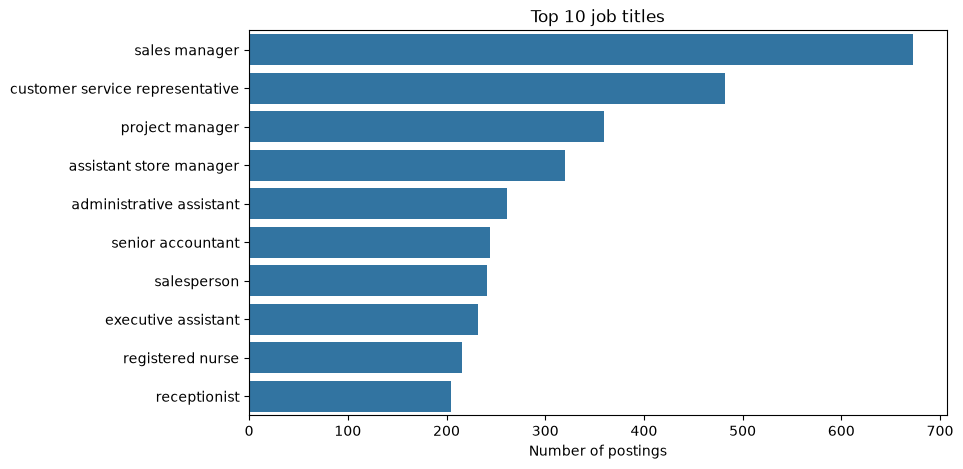

In [5]:
top_titles = df["title"].value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_titles.values, y=top_titles.index)
plt.title("Top 10 job titles")
plt.xlabel("Number of postings")
plt.ylabel("")
plt.show()

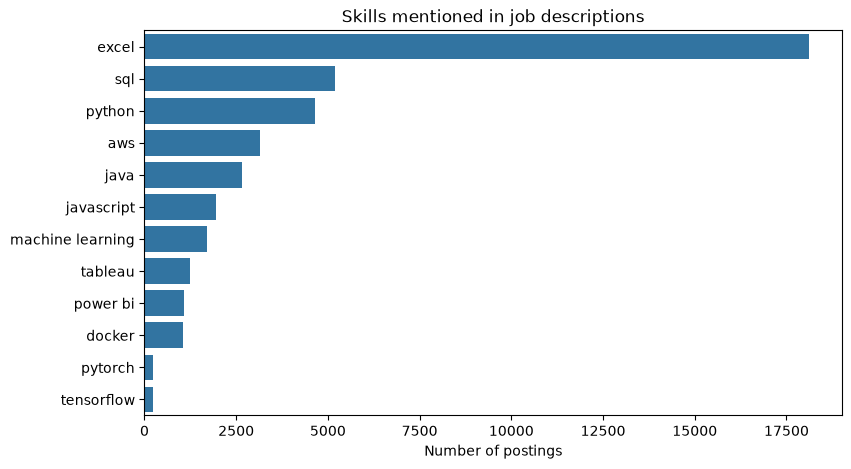

In [7]:
skills = ["python", "sql", "excel", "java", "javascript", "aws", "tableau",
          "power bi", "machine learning", "tensorflow", "pytorch", "docker"]

text = df["description"].fillna("").str.lower()

counts = {s: text.str.contains(rf"\b{s}\b", regex=True).sum() for s in skills}
skill_counts = pd.Series(counts).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=skill_counts.values, y=skill_counts.index)
plt.title("Skills mentioned in job descriptions")
plt.xlabel("Number of postings")
plt.ylabel("")
plt.show()

In [8]:
(skill_counts / len(df) * 100).round(1)

excel               14.6
sql                  4.2
python               3.8
aws                  2.6
java                 2.2
javascript           1.6
machine learning     1.4
tableau              1.0
power bi             0.9
docker               0.9
pytorch              0.2
tensorflow           0.2
dtype: float64

In [9]:
print("Total postings:", len(df))
print()
print("Top 10 job titles:")
print(df["title"].value_counts().head(10))
print()
print("Top 10 locations:")
print(df["location"].value_counts().head(10))
print()
print("Skill counts:")
print(skill_counts)
print()
print("Skill percentages of all postings:")
print((skill_counts / len(df) * 100).round(1))

Total postings: 123849

Top 10 job titles:
title
sales manager                      673
customer service representative    482
project manager                    360
assistant store manager            320
administrative assistant           261
senior accountant                  244
salesperson                        241
executive assistant                232
registered nurse                   216
receptionist                       205
Name: count, dtype: int64

Top 10 locations:
location
United States    8125
New York, NY     2756
Chicago, IL      1834
Houston, TX      1762
Dallas, TX       1383
Atlanta, GA      1363
Boston, MA       1176
Austin, TX       1083
Charlotte, NC    1075
Phoenix, AZ      1059
Name: count, dtype: int64

Skill counts:
excel               18107
sql                  5183
python               4648
aws                  3161
java                 2664
javascript           1961
machine learning     1710
tableau              1245
power bi             1069
docker      

In [10]:
print(skill_counts.to_string())
print()
print((skill_counts / len(df) * 100).round(1).to_string())

excel               18107
sql                  5183
python               4648
aws                  3161
java                 2664
javascript           1961
machine learning     1710
tableau              1245
power bi             1069
docker               1058
pytorch               243
tensorflow            224

excel               14.6
sql                  4.2
python               3.8
aws                  2.6
java                 2.2
javascript           1.6
machine learning     1.4
tableau              1.0
power bi             0.9
docker               0.9
pytorch              0.2
tensorflow           0.2


## Stage 1 findings: exploring the LinkedIn job postings data

**Dataset:** LinkedIn Job Postings (2023-2024) from Kaggle, with **123,849 postings** and 31 columns, including title, description, and location.

**Job titles**

- The most common job title is **sales manager** (673 postings), followed by **customer service representative** (482) and **project manager** (360).
- The rest of the top 10 are assistant store manager, administrative assistant, senior accountant, salesperson, executive assistant, registered nurse, and receptionist.
- Most of the top titles are in sales, administration, and customer service rather than tech, so this dataset covers the whole job market, not just technology roles.

**Locations**

- The most common value is simply **"United States"** (8,125 postings), which means many postings have no specific city.
- The most common cities are **New York, NY** (2,756), **Chicago, IL** (1,834), **Houston, TX** (1,762), **Dallas, TX** (1,383), **Atlanta, GA** (1,363), and **Boston, MA** (1,176).

**Skills mentioned in job descriptions**

| Skill | Postings | Share of all postings |
|---|---|---|
| Excel | 18,107 | 14.6% |
| SQL | 5,183 | 4.2% |
| Python | 4,648 | 3.8% |
| AWS | 3,161 | 2.6% |
| Java | 2,664 | 2.2% |
| JavaScript | 1,961 | 1.6% |
| Machine learning | 1,710 | 1.4% |
| Tableau | 1,245 | 1.0% |
| Power BI | 1,069 | 0.9% |
| Docker | 1,058 | 0.9% |
| PyTorch | 243 | 0.2% |
| TensorFlow | 224 | 0.2% |

- **Excel** is the most mentioned skill by far (14.6%), but this count is probably inflated because "excel" is also an ordinary verb ("excel in a team environment"), so it likely overstates the spreadsheet software.
- Among clearly technical skills, **SQL** (4.2%) leads, just ahead of **Python** (3.8%), followed by **AWS** (2.6%), **Java** (2.2%), and **JavaScript** (1.6%).
- **Machine learning** appears in 1.4% of postings, while the deep learning frameworks **PyTorch** and **TensorFlow** each appear in only 0.2%.

**Takeaways**

- Even the most requested technical skills appear in only a small share of postings, because most jobs in this dataset are not technical roles.
- SQL and Python are the most valuable skills to show in a project, so the job matcher should give them extra weight.
- Simple keyword counting is a useful first pass but is imperfect (the "excel" problem above), so later stages will use embeddings to understand meaning instead of matching words.

**Next step:** Stage 2 will train classical machine learning models to predict a job's category from its description.